In [1]:
import pandas as pd

# import 'Numpy'
import numpy as np

# import subpackage of Matplotlib
import matplotlib.pyplot as plt

# import 'Seaborn'
import seaborn as sns

# to suppress warnings
from warnings import filterwarnings
filterwarnings('ignore')

# display all columns of the dataframe
pd.options.display.max_columns = None

# display all rows of the dataframe
pd.options.display.max_rows = None

# to display the float values upto 6 decimal places
pd.options.display.float_format = '{:.6f}'.format

# import train-test split
from sklearn.model_selection import train_test_split
# import various functions from statsmodels
import statsmodels.api as sm

# import various functions from sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score

In [2]:
plt.rcParams['figure.figsize'] = [8,4]

In [3]:
df_dietanic = pd.read_csv("Titanic-Dataset.csv")
df_dietanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000000,1,0,A/5 21171,7.250000,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.000000,1,0,PC 17599,71.283300,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000000,0,0,STON/O2. 3101282,7.925000,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000000,1,0,113803,53.100000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000000,0,0,373450,8.050000,NaN,S


In [4]:
df_dietanic.shape

(891, 12)

In [5]:
df_dietanic.dtypes

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object

In [6]:
df_dietanic = df_dietanic.drop(["PassengerId","Name","Ticket","Cabin"], axis = 1)

In [7]:
df_dietanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


In [8]:
# isnull().sum(): calculate the null values in each column for dataset
# sort_values(ascending=False): sort the values in descending order of values
total = df_dietanic.isnull().sum().sort_values(ascending=False)

# isnull().sum(): calculate the null values in each column for dataset
# isnull().count(): calculate the count values in each column for dataset
# sort_values(ascending=False): sort the values in descending order of values
percent = (df_dietanic.isnull().sum()/df_dietanic.isnull().count()).sort_values(ascending=False)

# concat(): append dataframes
# axis=1: append by column
# keys: specify column name
missing_data = pd.concat([total, percent], axis=1, keys=['Total', 'Percent'])

# display dataframe of missing values
missing_data

,Total,Percent
Age,177,0.198653
Embarked,2,0.002245
Survived,0,0.000000
Pclass,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000
Fare,0,0.000000


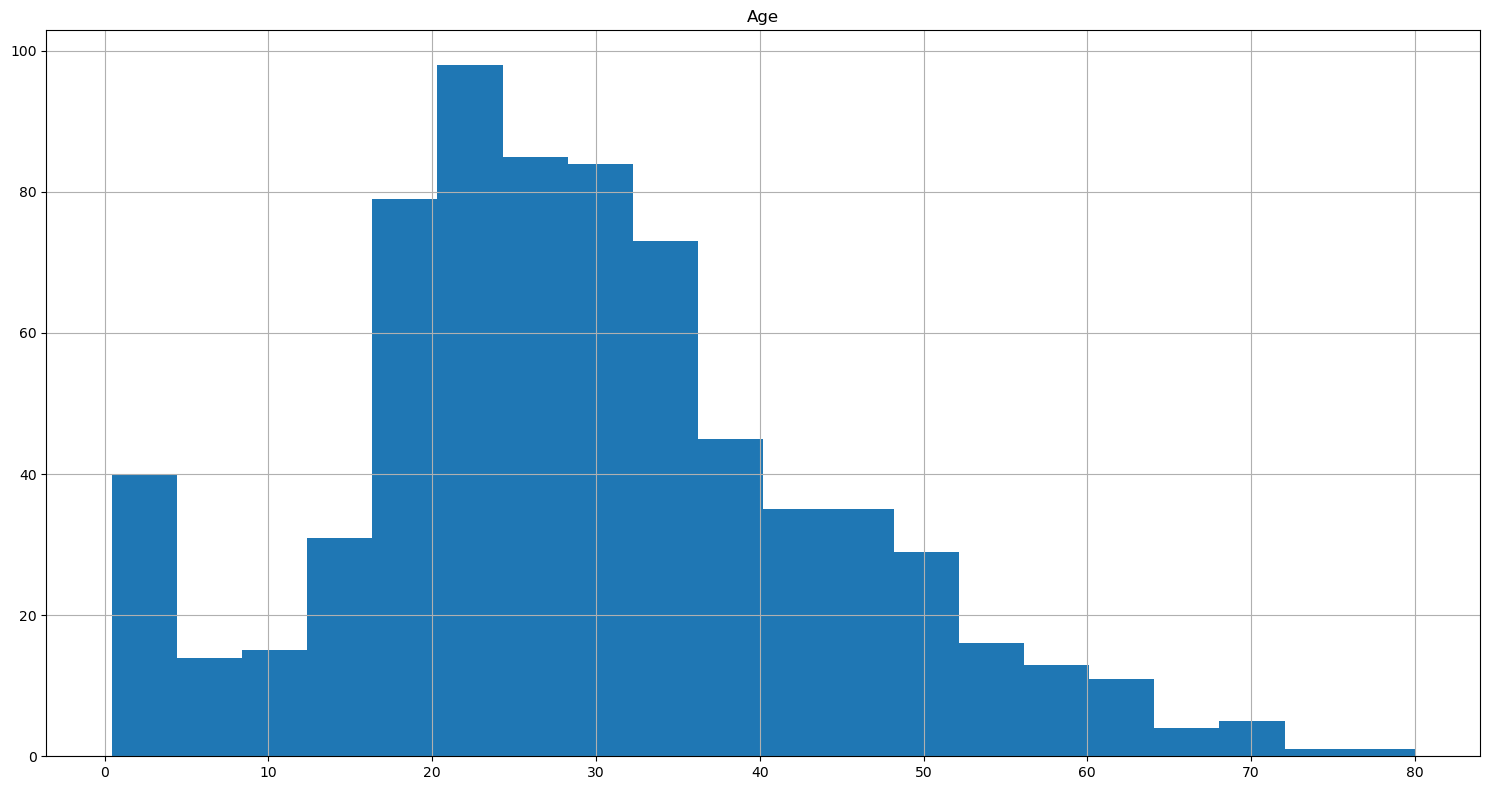

In [9]:
# extract all the variables with missing values in a new dataframe 'df_missing_values'
df_missing_values = df_dietanic[['Age']]

# plot histogram of all variables which have missing values
# set the number of bins to 20
# set the figure size using 'figsize'
df_missing_values.hist(bins = 20, figsize = (15,8))

# adjust the subplots
plt.tight_layout()

# display the plot
plt.show()

In [10]:
df_dietanic['Age'].skew()

np.float64(0.38910778230082704)

In [11]:
df_dietanic['Age'] = df_dietanic['Age'].fillna(df_dietanic['Age'].mean())
df_dietanic['Embarked'] = df_dietanic['Embarked'].fillna(df_dietanic['Embarked'].mode()[0])

In [12]:
df_dietanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    object 
dtypes: float64(2), int64(4), object(2)
memory usage: 55.8+ KB


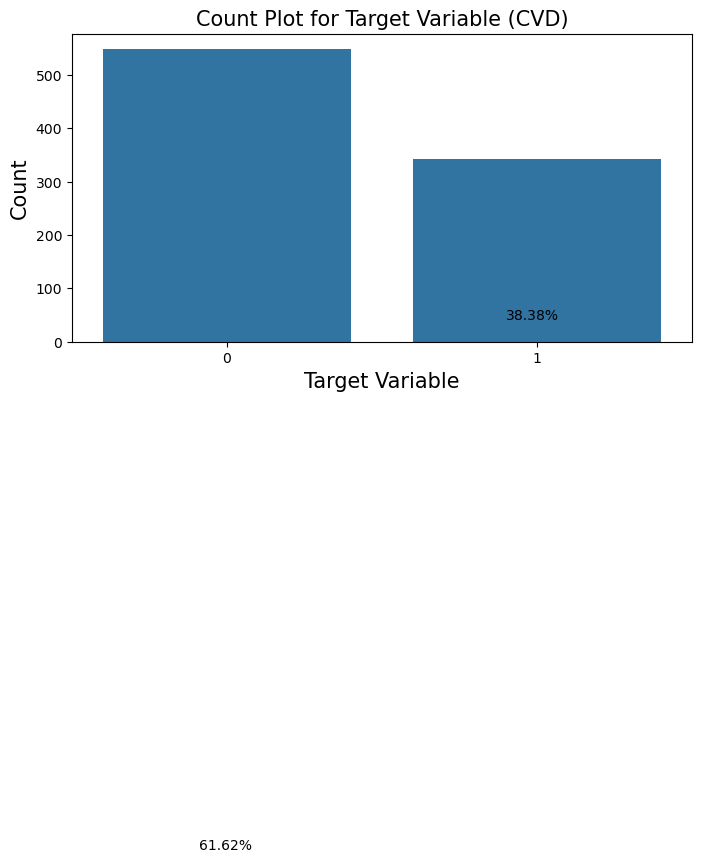

In [13]:
# consider only the target variable
df_target = df_dietanic['Survived']

# get counts of 0's and 1's in the 'Loan_Status' variable
df_target.value_counts()

# plot the countplot of the variable 'Loan_Status'
sns.countplot(x = df_target)

# use below code to print the percentage values in the graph
# 'x' and 'y' gives position of the text
# 's' is the text to be printed
plt.text(x = -0.09, y = df_target.value_counts()[0] - 1500, s = str(round((df_target.value_counts()[0])*100/len(df_target),2)) + '%')
plt.text(x = 0.90, y = df_target.value_counts()[1] - 300, s = str(round((df_target.value_counts()[1])*100/len(df_target),2)) + '%')

# add plot and axes labels
# set text size using 'fontsize'
plt.title('Count Plot for Target Variable (CVD)', fontsize = 15)
plt.xlabel('Target Variable', fontsize = 15)
plt.ylabel('Count', fontsize = 15)

# to show the plot
plt.show()

In [14]:
df_target.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [15]:
df_dietanic['Pclass'] = df_dietanic['Pclass'].astype('object')

type('Pclass')

str

In [16]:
df_numeric=df_dietanic.select_dtypes(include=np.number).drop(["Survived"],axis=1)

scaler = StandardScaler()
num_scale = scaler.fit_transform(df_numeric)
df_num=pd.DataFrame(num_scale,columns=df_numeric.columns)

df_categorical=df_dietanic.select_dtypes(include='object')
df_cat=pd.get_dummies(df_categorical,drop_first=True)

X=pd.concat([df_num,df_cat],axis=1)
y=df_dietanic.Survived

X=sm.add_constant(X)
X=X.astype('float')
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=1, test_size = 0.2)
logreg_full=sm.Logit(y_train,X_train).fit()
print(logreg_full.summary())

Optimization terminated successfully.
         Current function value: 0.430208
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:               Survived   No. Observations:                  712
Model:                          Logit   Df Residuals:                      702
Method:                           MLE   Df Model:                            9
Date:                Mon, 01 Jun 2026   Pseudo R-squ.:                  0.3511
Time:                        12:20:40   Log-Likelihood:                -306.31
converged:                       True   LL-Null:                       -472.04
Covariance Type:            nonrobust   LLR p-value:                 5.419e-66
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8811      0.361      7.982      0.000       2.174       3.588
Age           -0.5284      0.

In [17]:
#AIC Score:
print('AIC:',logreg_full.aic)

AIC: 632.6164603837585


In [18]:
y_pred_prob = logreg_full.predict(X_test)
y_pred = [ 0 if x < 0.5 else 1 for x in y_pred_prob]
cm = confusion_matrix(y_test, y_pred)
TN = cm[0,0]
TP = cm[1,1]
FP = cm[0,1]
FN = cm[1,0]
accuracy = (TN+TP) / (TN+FP+FN+TP)
print("Accuracy:", accuracy)

Accuracy: 0.7932960893854749


In [19]:
Precision=(TP)/(TP+FP)*100
Precision

np.float64(77.27272727272727)

In [20]:
Recall=(TP)/(TP+FN)*100
Recall

np.float64(69.86301369863014)

In [21]:
Specificity=(TN)/(TN+FP)*100
Specificity

np.float64(85.84905660377359)

In [22]:
#Accuracy Score & F1 Score
print("Accuracy:",accuracy_score(y_test, y_pred))
print("F1 score:",f1_score(y_test, y_pred))

Accuracy: 0.7932960893854749
F1 score: 0.7338129496402878


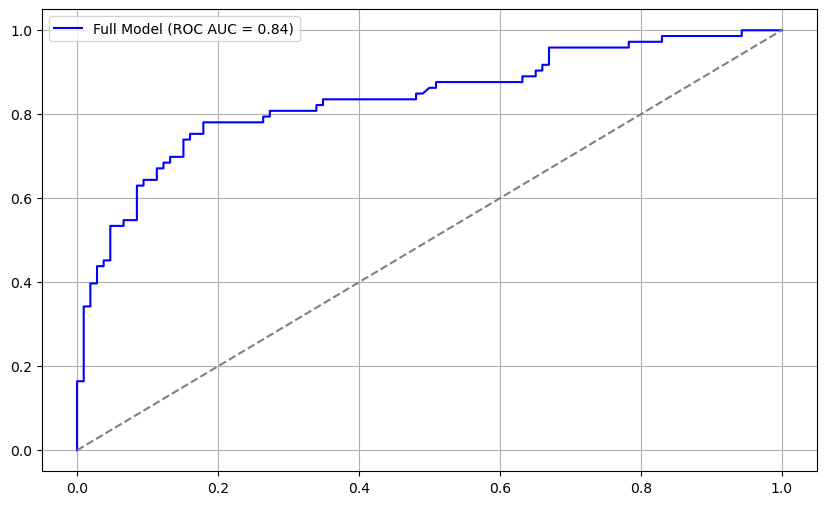

In [23]:
#ROC Curve & AUC:
y_prob_full = logreg_full.predict(X_test)
roc_auc_full = roc_auc_score(y_test, y_prob_full)
fpr_full, tpr_full, _ = roc_curve(y_test, y_prob_full)
plt.figure(figsize=(10, 6))
plt.plot(fpr_full, tpr_full, color='blue', label=f'Full Model (ROC AUC = {roc_auc_full:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
Precision=(TP)/(TP+FP)*100
Precision

np.float64(77.27272727272727)

In [25]:
#Building the KNN Model:
knn_model = KNeighborsClassifier(n_neighbors = 3, metric='euclidean').fit(X_train, y_train)
y_pred = knn_model.predict(X_test)
print("Accuracy:",accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7597765363128491
              precision    recall  f1-score   support

           0       0.77      0.85      0.81       106
           1       0.74      0.63      0.68        73

    accuracy                           0.76       179
   macro avg       0.76      0.74      0.74       179
weighted avg       0.76      0.76      0.76       179



In [26]:
#Building the Gaussian Naive Bayes Model:
gnb_model = GaussianNB().fit(X_train, y_train)
y_pred = gnb_model.predict(X_test)

# print the classification report 
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.84      0.80       106
           1       0.73      0.63      0.68        73

    accuracy                           0.75       179
   macro avg       0.75      0.73      0.74       179
weighted avg       0.75      0.75      0.75       179



1. Decision tree
Image	
Outliers detection and removal

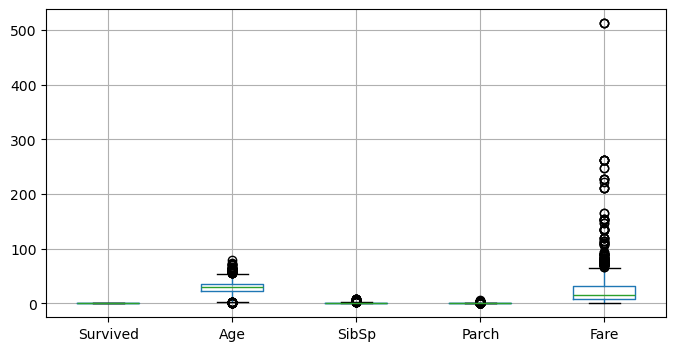

In [27]:
df_dietanic.boxplot()
plt.show()

In [28]:
num_cols=df_dietanic.select_dtypes(include='number')
q1=num_cols.quantile(0.25)
q3=num_cols.quantile(0.75)
iqr=q3-q1
mask=~((num_cols <(q1-1.5*iqr))|(num_cols>(q3+1.5*iqr))).any(axis=1)
df_dietanic=df_dietanic[mask].reset_index(drop=True)
df_dietanic.shape

(577, 8)

In [29]:
df_dietanic["Survived"].value_counts()

Survived
0    404
1    173
Name: count, dtype: int64

In [30]:
from sklearn.tree import DecisionTreeClassifier
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from sklearn import tree

In [37]:
df_target=df_dietanic['Survived']
df_feature=df_dietanic.drop('Survived',axis=1)
df_num=df_feature.select_dtypes(include=[np.number])
df_cat=df_feature.select_dtypes(include=['object'])
dummy_var=pd.get_dummies(data=df_cat,drop_first=True)
X=pd.concat([df_num,dummy_var],axis=1)
X.head()

,Age,SibSp,Parch,Fare,Pclass_2,Pclass_3,Sex_male,Embarked_Q,Embarked_S
0,22.000000,1,0,7.250000,False,True,True,False,True
1,26.000000,0,0,7.925000,False,True,False,False,True
2,35.000000,1,0,53.100000,False,False,False,False,True
3,35.000000,0,0,8.050000,False,True,True,False,True
4,29.699118,0,0,8.458300,False,True,True,True,False


In [38]:
X_train,X_test,y_train,y_test=train_test_split(X,df_target,random_state=100,test_size=0.3)
dt_full=DecisionTreeClassifier(random_state=100).fit(X_train,y_train)
y_pred_full=dt_full.predict(X_test)
important_features=pd.DataFrame({'Feature':X_train.columns,'Importance':dt_full.feature_importances_})
important_features.sort_values(by='Importance',ascending=False)

,Feature,Importance
3,Fare,0.322734
0,Age,0.251619
6,Sex_male,0.224756
5,Pclass_3,0.078007
8,Embarked_S,0.069102
1,SibSp,0.038844
4,Pclass_2,0.008043
7,Embarked_Q,0.006894
2,Parch,0.000000


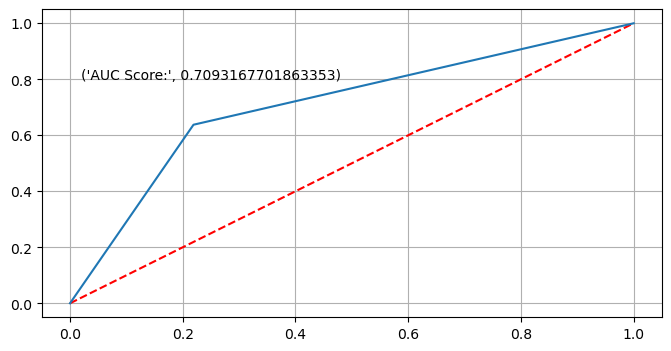

In [39]:
fpr,tpr,threshold=roc_curve(y_test,y_pred_full)
plt.plot([0,1],[0,1],'r--')
plt.plot(fpr,tpr)
plt.text(x=0.02,y=0.8,s=('AUC Score:',metrics.roc_auc_score(y_test,y_pred_full)))
plt.grid(True)
plt.show()

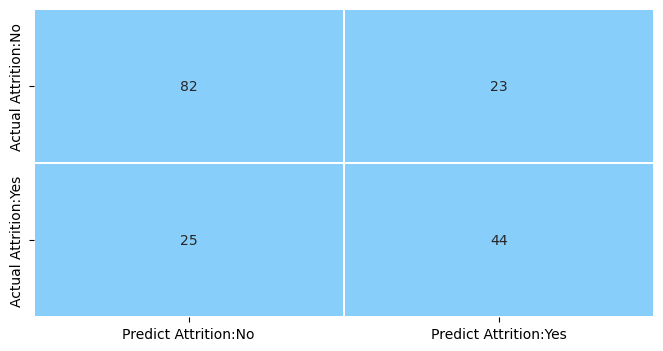

In [40]:
cm=confusion_matrix(y_test,y_pred_full)
conf_matrix=pd.DataFrame(data=cm,columns=['Predict Attrition:No','Predict Attrition:Yes'],index=['Actual Attrition:No','Actual Attrition:Yes'])
sns.heatmap(conf_matrix,annot=True,fmt='d',cmap=ListedColormap(['lightskyblue']),cbar=False,linewidths=0.2)
plt.show()

In [41]:
tn=cm[0][0]
tp=cm[1][1]
fp=cm[0][1]
fn=cm[1][0]
total=tn+tp+fp+fn
correct_classify=((tn+tp)/total)*100
print('Correct Classify:',correct_classify)
incorrect_classify=((fp+fn)/total)*100
print('Incorrect Classify:',incorrect_classify)
specificity=tn/(tn+fp)
print('Specificity:',specificity)
sensitivity=tp/(tp+fn)
print('sensitivity:',sensitivity)

Correct Classify: 72.41379310344827
Incorrect Classify: 27.586206896551722
Specificity: 0.780952380952381
sensitivity: 0.6376811594202898


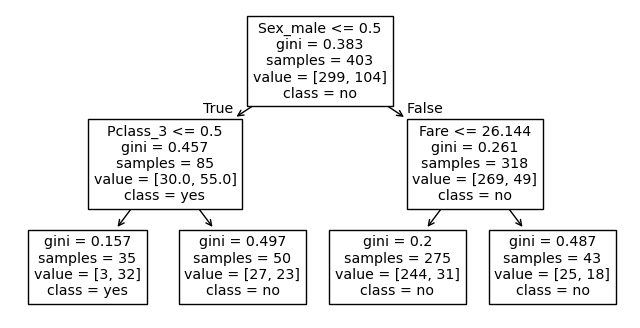

In [42]:
dt_2=DecisionTreeClassifier(max_leaf_nodes=4,random_state=100).fit(X_train,y_train)
tree.plot_tree(dt_2,class_names=['no','yes'],feature_names=X_train.columns)
plt.show()